In [1]:
import numpy as np
from netCDF4 import Dataset
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib import colors

import matplotlib.gridspec as gridspec
import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.crs as ccrs
import string

import iris
import iris.quickplot as qplt 
import iris.plot as iplt
iris.FUTURE.netcdf_promote=True
import iris.coord_categorisation

from iris.analysis import stats
from iris.analysis import maths
import xarray as xr

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/matplotlib/ticker.py:1693: UserWarning: Steps argument should be a sequence of numbers
increasing from 1 to 10, inclusive. Behavior with
values outside this range is undefined, and will
raise a ValueError in future versions of mpl.
  warnings.warn('Steps argument should be a sequence of numbers\n'


In [2]:
## Open observations
# Oxygen
path_obs_o2 = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/woa23_oxygen_1971-2000_v2.nc'
o2_constraint_obs = iris.Constraint(cube_func=lambda cube: cube.var_name == 'o_an')
o2_obs = iris.load_cube(path_obs_o2, o2_constraint_obs) 
o2_obs = iris.util.squeeze(o2_obs)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1808: UserWarning: Ignoring netCDF variable 'o_sea' invalid units 'micromoles_per_kilogram'
  warnings.warn(msg)
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iri

In [3]:
## PI
path = '/nfs/hera1/ee22kvcs/PMIP4/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['o2_Omon_ACCESS-ESM1-5_pi_100ymean_regridded_360x385_intlevel.nc',
                   'o2_Oyr_HadCM3_piControl_r1i1p1f1_5021-5120_regridded_385x360_ann_mean_intlevel.nc',
                   'o2_Oyr_IPSL-CM6A-LR_piControl_r1i1p1f1_gn_3550-3849_fixed_regridded_360x385_100yr_mean_intlevel.nc',
                   'o2_Oyr_KCM_piControl_r1i1p1f1_6401_6500_100yr_mean_intlevel.nc',
                   'o2_Omon_MIROC-ES2L_piControl_r1i1p1f2_gr1_225001-234912_regridded_360x385_100yr_mean_intlevel.nc',
                   'o2_Oyr_NorESM1-F_piControl_r1i1p1f1_gr_1601-1700_100yr_mean_regridded_360x385_intlevel.nc',
                   'o2_Oyr_NorESM2-LM_piControl_r1i1p1f1_gr_2001-2100_regridded_100yr_mean_intlevel.nc',]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'otracer13'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2')]

PI_models_o2 = []
for i in range(np.size(models)):
    uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    PI_models_o2.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'areacello', referenced by netCDF variable 'o2'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'volcello', referenced by netCDF variable 'o2'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversi

In [4]:
### LIG
path = '/nfs/hera1/ee22kvcs/PMIP4/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['o2_Omon_ACCESS-ESM1-5_lig_100ymean_regridded_360x385_intlevel.nc',
                   'o2_Oyr_HadCM3_lig127k_r1i1p1f1_6651-6750_regridded_385x360_ann_mean_intlevel.nc',
                   'o2_Oyr_IPSL-CM6A-LR_lig127k_r1i1p1f1_gn_1850-1949_regridded_360x385_100yr_mean_intlevel.nc',
                   'o2_Oyr_KCM_lig127k_r1i1p1f1_4901_5000_100yr_mean_intlevel.nc',
                   'o2_Omon_MIROC-ES2L_lig127k_r1i1p1f2_gr1_330001-339912_regridded_360x385_100yr_mean_intlevel.nc',
                   'o2_Oyr_NorESM1-F_lig127k_r1i1p1f1_gr_1601-1700_100yr_mean_regridded_360x385_intlevel.nc',
                   'o2_Oyr_NorESM2-LM_lig127k_r1i1p1f1_gr_2101-2200_100yr_mean_regridded_360x385_intlevel.nc',]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2_raw'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'otracer13'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2')]

LIG_models_o2 = []
for i in range(np.size(models)):
    uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    LIG_models_o2.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [5]:
### Open masks
## Obs.
path_mask_atl_obs = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Atlantic_ocean_WOA.nc'
path_mask_pac_obs = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Pacific_ocean_WOA.nc'
path_mask_ind_obs = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Indian_ocean_WOA.nc'
masks_obs = iris.Constraint(cube_func=lambda cube: cube.var_name == 'mask')
## Open
atlantic_mask_obs = iris.load_cube(path_mask_atl_obs, masks_obs)
pacific_mask_obs = iris.load_cube(path_mask_pac_obs, masks_obs)
indian_mask_obs = iris.load_cube(path_mask_ind_obs, masks_obs)

## Models
path_mask_atl = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Atlantic_ocean_NorESM2-LM.nc'
path_mask_pac = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Pacific_ocean_NorESM2-LM.nc'
path_mask_ind = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Indian_ocean_NorESM2-LM.nc'
masks = iris.Constraint(cube_func=lambda cube: cube.var_name == 'mask')
## Open
atlantic_mask = iris.load_cube(path_mask_atl, masks)
pacific_mask = iris.load_cube(path_mask_pac, masks)
indian_mask = iris.load_cube(path_mask_ind, masks)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

### Broadcast masks

In [6]:
def broadcast_masks_to_models(models, atlantic_mask, pacific_mask, indian_mask):
    "Input: lists iof iris cubes.Output: dictionary of broadcasted mask cubes by basin"
    broadcasted_masks = {"atlantic": [], "pacific": [], "indian": []}
    
    for model in models:
        shape = model.shape  # (depth, lat, lon) or similar
        
        # Broadcast each mask
        atl_broadcast = np.broadcast_to(atlantic_mask.data, shape)
        pac_broadcast = np.broadcast_to(pacific_mask.data, shape)
        ind_broadcast = np.broadcast_to(indian_mask.data, shape)
        
        # Replace NaNs with masked values
        atl_masked = np.ma.masked_invalid(atl_broadcast)
        pac_masked = np.ma.masked_invalid(pac_broadcast)
        ind_masked = np.ma.masked_invalid(ind_broadcast)
        
        # Create cubes with the same metadata as the model
        broadcasted_masks["atlantic"].append(model.copy(data=atl_masked))
        broadcasted_masks["pacific"].append(model.copy(data=pac_masked))
        broadcasted_masks["indian"].append(model.copy(data=ind_masked))
    
    return broadcasted_masks

In [7]:
woa_masks = broadcast_masks_to_models([o2_obs], atlantic_mask_obs, pacific_mask_obs, indian_mask_obs)

In [8]:
masks_LIG = broadcast_masks_to_models(LIG_models_o2, atlantic_mask, pacific_mask, indian_mask)
masks_PI = broadcast_masks_to_models(PI_models_o2, atlantic_mask, pacific_mask, indian_mask)

### Setup the data

In [9]:
### Obs data
atlantic_masked_woa = o2_obs * woa_masks["atlantic"][0]
indian_masked_woa = o2_obs * woa_masks["indian"][0]
pacific_masked_woa = o2_obs * woa_masks["pacific"][0]
#### Obs zonal means
atl_an_zmean_o2_obs = atlantic_masked_woa.collapsed('longitude', iris.analysis.MEAN)
ind_an_zmean_o2_obs = indian_masked_woa.collapsed('longitude', iris.analysis.MEAN)
pac_an_zmean_o2_obs = pacific_masked_woa.collapsed('longitude', iris.analysis.MEAN)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:988: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(self.dtype, np.str):


In [10]:
### LIG data by basin
atlantic_masked_LIG_models = [m * mask for m, mask in zip(LIG_models_o2, masks_LIG["atlantic"])]
indian_masked_LIG_models = [m * mask for m, mask in zip(LIG_models_o2, masks_LIG["indian"])]
pacific_masked_LIG_models = [m * mask for m, mask in zip(LIG_models_o2, masks_LIG["pacific"])]
#### LIG zonal means
atl_an_zmean_o2_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_LIG_models]
ind_an_zmean_o2_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_LIG_models]
pac_an_zmean_o2_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_LIG_models]

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:988: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(self.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:1017: UserWarning: Collapsing a non-contiguous coordinate. Metadata may not be fully descriptive for 'longitude'.
  warnings.warn(msg.format(self.name()))


In [11]:
### PI data by basin
atlantic_masked_PI_models = [m * mask for m, mask in zip(PI_models_o2, masks_PI["atlantic"])]
indian_masked_PI_models = [m * mask for m, mask in zip(PI_models_o2, masks_PI["indian"])]
pacific_masked_PI_models = [m * mask for m, mask in zip(PI_models_o2, masks_PI["pacific"])]
#### PI zonal means
atl_an_zmean_o2_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_PI_models]
ind_an_zmean_o2_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_PI_models]
pac_an_zmean_o2_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_PI_models]

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:988: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(self.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:1017: UserWarning: Collapsing a non-contiguous coordinate. Metadata may not be fully descriptive for 'longitude'.
  warnings.warn(msg.format(self.name()))


### Plot Obs and PI

/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:3337: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  _data[indx] = dval
/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:3340: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  _mask[indx] = mval


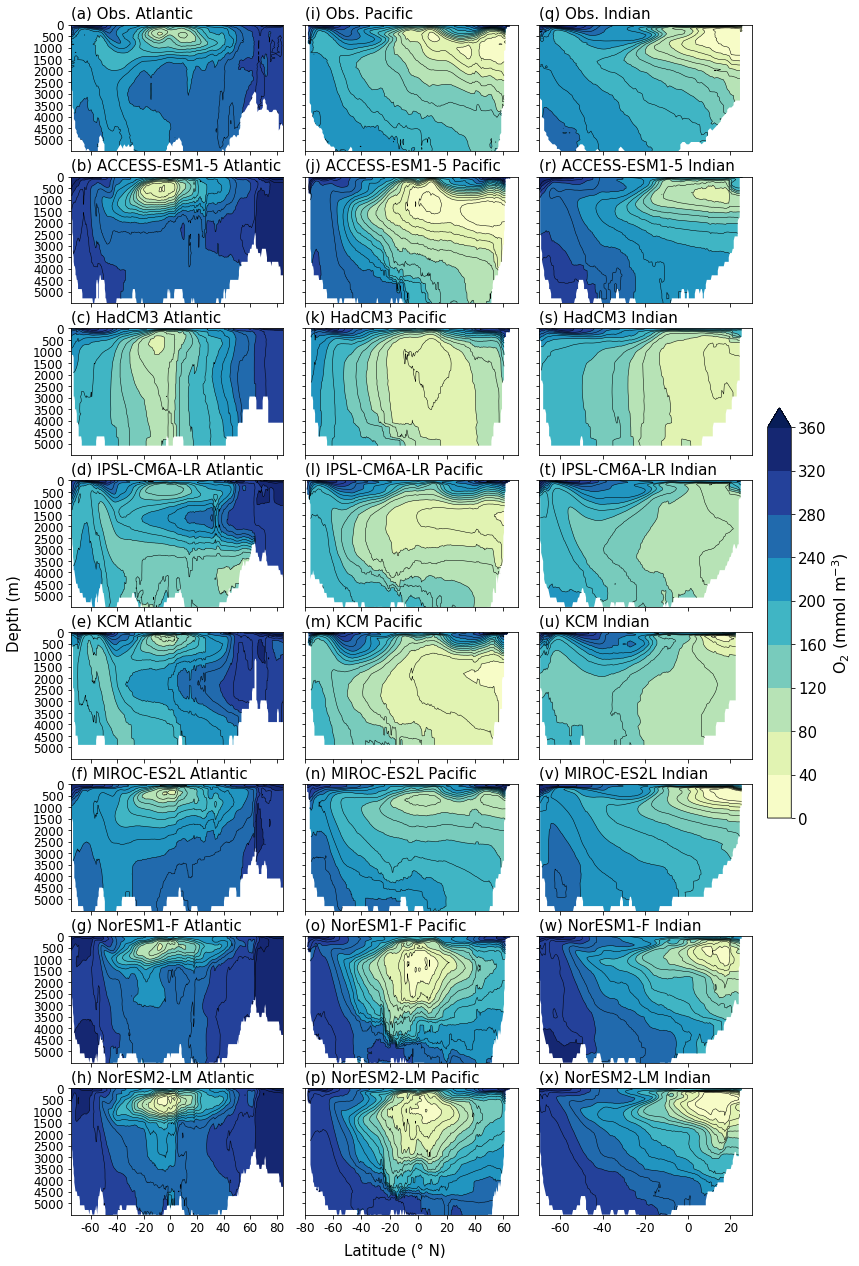

In [12]:
fig = plt.figure(figsize=(11, 19))

n_models = 8
n_basins = 3

axes = np.empty((n_models, n_basins), dtype=object)
for i in range(n_models):
    for j in range(n_basins):
        idx = i * n_basins + j + 1
        axes[i, j] = fig.add_subplot(n_models, n_basins, idx)

model_names = ['Obs.', 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR','KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
basin_names = ['Atlantic', 'Pacific', 'Indian']

simulations_list = [
    [atl_an_zmean_o2_obs] + atl_an_zmean_o2_PI,
    [pac_an_zmean_o2_obs] + pac_an_zmean_o2_PI,
    [ind_an_zmean_o2_obs] + ind_an_zmean_o2_PI,]

depth = ['depth', 'depth', 'depth_1', 'Vertical T levels', 'plev','ocean sigma over z coordinate', 'depth', 'depth']

# Letters
letters = list(string.ascii_lowercase)
letter_cols = [letters[0:8], letters[8:16], letters[16:24]]

levels  = np.arange(0, 360+40, 40)
levels2 = np.arange(0, 360+20, 20)

im = None

for j, simulations in enumerate(simulations_list):
    for n in range(n_models):
        ax = axes[n, j]
        ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.set_xticklabels([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)
        ax.set_ylim(0, 5500)
        
        # tick positions, labels
        ax.set_yticks(np.arange(0, 5000+500, 500))
        if j == 0:
            ax.tick_params(axis='y', labelsize=12)
        else:
            ax.set_yticklabels([])

        if n == n_models - 1:
            ax.set_xticklabels(ax.get_xticks(), fontsize=12)
        else:
            ax.set_xticklabels([])
        #----------------------------------------------
        if j == 0:
            ax.set_xlim(-75, 85)
        elif j == 1:
            ax.set_xlim(-80, 70)
        else:
            ax.set_xlim(-70, 30)

        letter = letter_cols[j][n]
        title_str = "(" + letter + ") " + model_names[n] + " " + basin_names[j]
        ax.set_title(title_str, fontsize=15, loc='left')
        
        # unit conversion
        cube_n = simulations[n]
        if n == 4:
            data = cube_n * 1e6
        elif n in (3, 5, 6, 7):
            data = cube_n * 1e3
        else:
            data = cube_n
        # plot
        im = iplt.contourf(data, coords=['latitude', depth[n]], axes=ax, levels=levels, cmap='YlGnBu', extend='max')
        im2 = iplt.contour(data, coords=['latitude', depth[n]], axes=ax, colors='k', levels=levels2, linewidths=0.5)

        if n in [2, 3, 4, 5]:
            ax.invert_yaxis()

# colourbar
fig.subplots_adjust(left=0.12, right=0.88, top=0.95, bottom=0.05, wspace=0.1, hspace=0.1)
cbar_ax = fig.add_axes([0.97, 0.35, 0.03, 0.3])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.ax.set_ylabel('O$_2$ (mmol m$^{-3}$)', size=16)
cbar.ax.tick_params(labelsize=15)

# Axis labels
fig.text(0.01, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=15)
fig.text(0.5, 0.03, 'Latitude (° N)', ha='center', fontsize=15)

plt.subplots_adjust(left=0.09, bottom=0.06, right=0.95, top=0.93, wspace=0.1, hspace=0.2)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/O2_zonally_mean_PI_3basins_v2.png', bbox_inches='tight', dpi=300, format='png')
plt.show()

### Differences (LIG-PI)

In [13]:
### Differences
diff_o2_atl = []
diff_o2_pac = []
diff_o2_ind = []

for i in range (np.size(atl_an_zmean_o2_PI)):
    diff_atl = atl_an_zmean_o2_LIG[i].data-atl_an_zmean_o2_PI[i].data
    diff_pac = pac_an_zmean_o2_LIG[i].data-pac_an_zmean_o2_PI[i].data
    diff_ind = ind_an_zmean_o2_LIG[i].data-ind_an_zmean_o2_PI[i].data

    diff_atl_cube = atl_an_zmean_o2_PI[i].copy(data = diff_atl)
    diff_pac_cube = pac_an_zmean_o2_PI[i].copy(data = diff_pac)
    diff_ind_cube = ind_an_zmean_o2_PI[i].copy(data = diff_ind)
    
    diff_o2_atl.append(diff_atl_cube)
    diff_o2_pac.append(diff_pac_cube)
    diff_o2_ind.append(diff_ind_cube)

/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:3337: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  _data[indx] = dval
/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:3340: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  _mask[indx] = mval


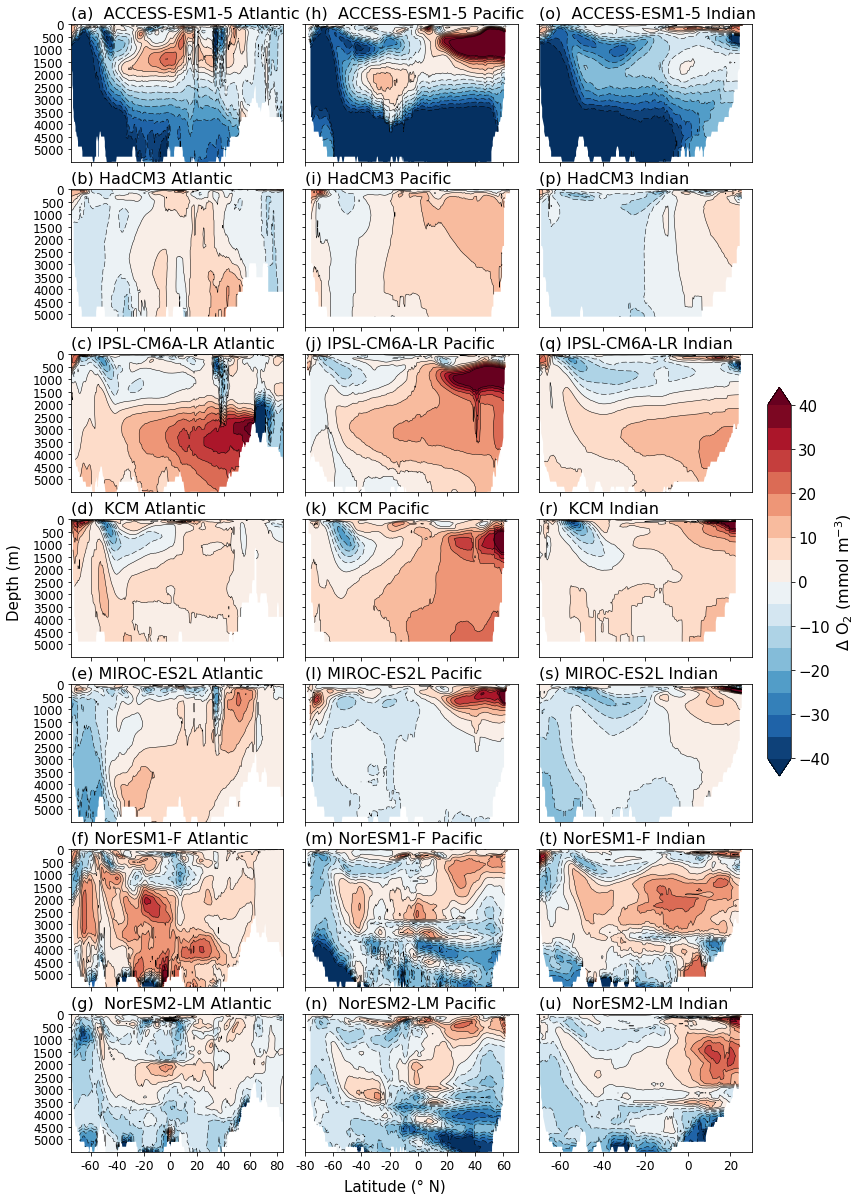

In [14]:
fig = plt.figure(figsize=(11, 18))

n_models = len(models)
n_basins = 3

axes = np.empty((n_models, n_basins), dtype=object)
for i in range(n_models):
    for j in range(n_basins):
        idx = i * n_basins + j + 1
        axes[i, j] = fig.add_subplot(n_models, n_basins, idx)

model_names = [' ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', ' KCM', 'MIROC-ES2L', 'NorESM1-F', ' NorESM2-LM']
basin_names = ['Atlantic', 'Pacific', 'Indian']
simulations_list = [diff_o2_atl, diff_o2_pac, diff_o2_ind]
depth = ['depth', 'depth_1', 'Vertical T levels', 'plev', 'ocean sigma over z coordinate', 'depth', 'depth']

# Letters
letters = list(string.ascii_lowercase)
letter_cols = [letters[0:7], letters[7:14], letters[14:21]]

levels = np.arange(-40, 40+5, 5)
levels2 = np.arange(-40, 40+5, 5)

im = None

for j, simulations in enumerate(simulations_list):
    for n in range(n_models):
        ax = axes[n, j]
        ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.set_xticklabels([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)
        ax.set_ylim(0, 5500)
        
        # tick positions
        ax.set_yticks(np.arange(0, 5000+500, 500))
        if j == 0:
            ax.tick_params(axis='y', labelsize=12)
        else:
            ax.set_yticklabels([])

        if n == n_models - 1:
            ax.set_xticklabels(ax.get_xticks(), fontsize=12)
        else:
            ax.set_xticklabels([])
        #----------------------------------------------
        if j == 0:
            ax.set_xlim(-75, 85)
        elif j == 1:
            ax.set_xlim(-80, 70)
        else:
            ax.set_xlim(-70, 30)

        letter = letter_cols[j][n]
        title_str = "(" + letter + ") " + model_names[n] + " " + basin_names[j]
        ax.set_title(title_str, fontsize=16, loc='left')
        
        # unit conversion
        cube_n = simulations[n]
        if n == 3:
            data = cube_n * 1e6
        elif n in (2, 4, 5, 6):
            data = cube_n * 1e3
        else:
            data = cube_n
        #------------------------------------------------
        im = iplt.contourf(data, coords=['latitude', depth[n]], axes=ax, levels=levels, cmap='RdBu_r', extend='both')
        im2 = iplt.contour(data, coords=['latitude', depth[n]], axes=ax, colors='k', levels=levels2, linewidths=0.5)

        if n in [1, 2, 3, 4]:
            ax.invert_yaxis()

# colourbar
fig.subplots_adjust(left=0.12, right=0.88, top=0.95, bottom=0.05, wspace=0.1, hspace=0.1)
cbar_ax = fig.add_axes([0.97, 0.35, 0.03, 0.3])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.ax.set_ylabel('Δ O$_2$ (mmol m$^{-3}$)', size=16)
cbar.ax.tick_params(labelsize=15)

# axis labels
fig.text(0.01, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=15)
fig.text(0.5, 0.03, 'Latitude (° N)', ha='center', fontsize=15)

plt.subplots_adjust(left=0.09, bottom=0.06, right=0.95, top=0.93, wspace=0.1, hspace=0.2)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/O2_zonally_mean_diff_3basins_v2.png', bbox_inches='tight', dpi=300, format='png')
plt.show()

### MMM PI

In [17]:
### PI
atl_an_zmean_o2_PI_converted = [cube.copy() for cube in atl_an_zmean_o2_PI]
pac_an_zmean_o2_PI_converted = [cube.copy() for cube in pac_an_zmean_o2_PI]
ind_an_zmean_o2_PI_converted = [cube.copy() for cube in ind_an_zmean_o2_PI]

## Unit conversions
# Atlantic
atl_an_zmean_o2_PI_converted[3].data = atl_an_zmean_o2_PI_converted[3].data * 1e6
for i in [2, 4, 5, 6]:
    atl_an_zmean_o2_PI_converted[i].data = atl_an_zmean_o2_PI_converted[i].data * 1e3
# Pacific
pac_an_zmean_o2_PI_converted[3].data = pac_an_zmean_o2_PI_converted[3].data * 1e6
for i in [2, 4, 5, 6]:
    pac_an_zmean_o2_PI_converted[i].data = pac_an_zmean_o2_PI_converted[i].data * 1e3
# Indian
ind_an_zmean_o2_PI_converted[3].data = ind_an_zmean_o2_PI_converted[3].data * 1e6
for i in [2, 4, 5, 6]:
    ind_an_zmean_o2_PI_converted[i].data = ind_an_zmean_o2_PI_converted[i].data * 1e3

# Calculate multi-model means
MMM_pi_o2_atl = sum([atl_an_zmean_o2_PI_converted[i].data for i in range(np.size(atl_an_zmean_o2_PI_converted))])/7
MMM_pi_o2_pac = sum([pac_an_zmean_o2_PI_converted[i].data for i in range(np.size(pac_an_zmean_o2_PI_converted))])/7
MMM_pi_o2_ind = sum([ind_an_zmean_o2_PI_converted[i].data for i in range(np.size(ind_an_zmean_o2_PI_converted))])/7

# Convert arrays to iris cubes
MMM_pi_o2_atl_cube = atl_an_zmean_o2_PI_converted[0].copy(data = MMM_pi_o2_atl)
MMM_pi_o2_pac_cube = pac_an_zmean_o2_PI_converted[0].copy(data = MMM_pi_o2_pac)
MMM_pi_o2_ind_cube = ind_an_zmean_o2_PI_converted[0].copy(data = MMM_pi_o2_ind)

In [18]:
### LIG
atl_an_zmean_o2_LIG_converted = [cube.copy() for cube in atl_an_zmean_o2_LIG]
pac_an_zmean_o2_LIG_converted = [cube.copy() for cube in pac_an_zmean_o2_LIG]
ind_an_zmean_o2_LIG_converted = [cube.copy() for cube in ind_an_zmean_o2_LIG]

## Unit conversions
# Atlantic
atl_an_zmean_o2_LIG_converted[3].data = atl_an_zmean_o2_LIG_converted[3].data * 1e6
for i in [2, 4, 5, 6]:
    atl_an_zmean_o2_LIG_converted[i].data = atl_an_zmean_o2_LIG_converted[i].data * 1e3
# Pacific
pac_an_zmean_o2_LIG_converted[3].data = pac_an_zmean_o2_LIG_converted[3].data * 1e6
for i in [2, 4, 5, 6]:
    pac_an_zmean_o2_LIG_converted[i].data = pac_an_zmean_o2_LIG_converted[i].data * 1e3
# Indian
ind_an_zmean_o2_LIG_converted[3].data = ind_an_zmean_o2_LIG_converted[3].data * 1e6
for i in [2, 4, 5, 6]:
    ind_an_zmean_o2_LIG_converted[i].data = ind_an_zmean_o2_LIG_converted[i].data * 1e3

# Calculate multi-model means
MMM_lig_o2_atl = sum([atl_an_zmean_o2_LIG_converted[i].data for i in range(np.size(atl_an_zmean_o2_LIG_converted))])/7
MMM_lig_o2_pac = sum([pac_an_zmean_o2_LIG_converted[i].data for i in range(np.size(pac_an_zmean_o2_LIG_converted))])/7
MMM_lig_o2_ind = sum([ind_an_zmean_o2_LIG_converted[i].data for i in range(np.size(ind_an_zmean_o2_LIG_converted))])/7

# Convert arrays to iris cubes
MMM_lig_o2_atl_cube = atl_an_zmean_o2_LIG_converted[0].copy(data = MMM_lig_o2_atl)
MMM_lig_o2_pac_cube = pac_an_zmean_o2_LIG_converted[0].copy(data = MMM_lig_o2_pac)
MMM_lig_o2_ind_cube = ind_an_zmean_o2_LIG_converted[0].copy(data = MMM_lig_o2_ind)

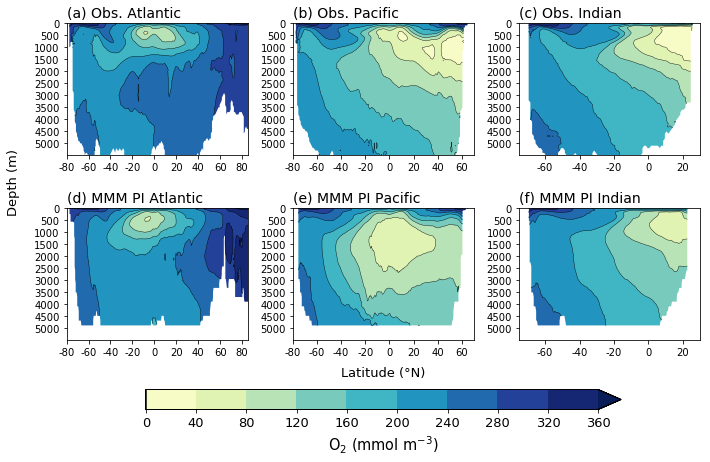

In [21]:
### Plot Obs with MMM
fig = plt.figure(figsize=(11, 5.5))

axes = []
for i in range(1,6+1):
    ax = fig.add_subplot(2, 3, i)
    axes.append(ax)
    
titles = [ '(a) Obs. Atlantic', '(b) Obs. Pacific', '(c) Obs. Indian',
          '(d) MMM PI Atlantic', '(e) MMM PI Pacific', '(f) MMM PI Indian']
simulations = [atl_an_zmean_o2_obs, pac_an_zmean_o2_obs, ind_an_zmean_o2_obs, 
               MMM_pi_o2_atl_cube, MMM_pi_o2_pac_cube, MMM_pi_o2_ind_cube]
depth = ['depth'] * 6


for (ax, t, n) in zip(axes, titles, range(np.size(simulations))):
    ax.set_yticks(np.arange(0, 5000+500, 500))
    ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80])
    ax.set_xticklabels([-80, -60, -40, -20, 0, 20, 40, 60, 80])
    ax.tick_params(axis='x', labelsize=10)
    ax.tick_params(axis='y', labelsize=10)
    ax.set_ylim(0, 5500)
    if n == 2 or n == 5: ## Indian
        ax.set_xlim(-75, 30)
    elif n == 1 or n == 4: ## Pacific
        ax.set_xlim(-80, 70)
    else: ## Atlantic
        ax.set_xlim(-80, 85)
    
    ax.set_title(t, fontsize=14, loc='left')
    levels = np.arange(0,360+40,40)
    
    im = iplt.contourf(simulations[n], coords=['latitude', depth[n]], axes = ax, levels = levels, cmap = 'YlGnBu', extend = 'max')
    im2 = iplt.contour(simulations[n], coords=['latitude', depth[n]], axes=ax, colors='k', levels = levels, linewidths=0.4)
    #ax.clabel(im2, levels3, inline=1, fontsize=6, fmt='%.0f')
    # Colourbar
    cbar_ax = fig.add_axes([0.2, -0.075, 0.6, 0.05])# [left, bottom, width, height] [0.92, 0.1, 0.02, 0.8]
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('O$_2$ (mmol m$^{-3}$)', size=14.5)
    #cbar.ax.xaxis.set_label_position('top')
    cbar.ax.tick_params(labelsize=13)

fig.text(0.025, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=13)
fig.text(0.5, 0.01, 'Latitude (°N)', ha='center', fontsize=13)
plt.subplots_adjust(left=0.1,bottom=0.1,right=0.9,top=0.9,wspace=0.25,hspace=0.4)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/O2_zonally_mean_PI_MMM_horiz.png', bbox_inches = 'tight', dpi=300, format='png')
plt.show()

### MMM differences

In [22]:
### MMM Diff
diff_o2_atl_converted = [cube.copy() for cube in diff_o2_atl]
diff_o2_pac_converted = [cube.copy() for cube in diff_o2_pac]
diff_o2_ind_converted = [cube.copy() for cube in diff_o2_ind]

# Atlantic
diff_o2_atl_converted[3].data = diff_o2_atl_converted[3].data * 1e6
for i in [2, 4, 5, 6]:
    diff_o2_atl_converted[i].data = diff_o2_atl_converted[i].data * 1e3
# Pacific
diff_o2_pac_converted[3].data = diff_o2_pac_converted[3].data * 1e6
for i in [2, 4, 5, 6]:
    diff_o2_pac_converted[i].data = diff_o2_pac_converted[i].data * 1e3
# Indian
diff_o2_ind_converted[3].data = diff_o2_ind_converted[3].data * 1e6
for i in [2, 4, 5, 6]:
    diff_o2_ind_converted[i].data = diff_o2_ind_converted[i].data * 1e3

# Calculate multi-model means
MMM_diff_atl = sum([diff_o2_atl_converted[i].data for i in range(np.size(diff_o2_atl_converted))])/7
MMM_diff_pac = sum([diff_o2_pac_converted[i].data for i in range(np.size(diff_o2_pac_converted))])/7
MMM_diff_ind = sum([diff_o2_ind_converted[i].data for i in range(np.size(diff_o2_ind_converted))])/7

# Convert arrays to iris cubes
MMM_diff_atl_cube = diff_o2_atl_converted[0].copy(data = MMM_diff_atl)
MMM_diff_pac_cube = diff_o2_pac_converted[0].copy(data = MMM_diff_pac)
MMM_diff_ind_cube = diff_o2_ind_converted[0].copy(data = MMM_diff_ind)

#### Spread

In [23]:
def calculate_threshold_agreement(dif_list, model_indices=[0,1,2,3,4,5,6], 
                                   threshold=1, min_models=5):
    "Calculate where at least min_models agree on change exceeding a threshold"
    # Stack all model differences into a 3D array (models, lat, depth)
    model_difs = np.array([dif_list[i].data for i in model_indices])

    # Count models exceeding thresholds
    positive_count = np.sum(model_difs > threshold, axis=0)
    negative_count = np.sum(model_difs < -threshold, axis=0)

    # Agreement mask
    agreement_mask = (positive_count >= min_models) | (negative_count >= min_models)

    # Non-agreement mask
    non_agreement_mask = ~agreement_mask

    return agreement_mask, non_agreement_mask

In [24]:
agreement_atl_thresh, non_agreement_atl_thresh = calculate_threshold_agreement(diff_o2_atl_converted, threshold=1, min_models=5)
agreement_ind_thresh, non_agreement_ind_thresh = calculate_threshold_agreement(diff_o2_ind_converted, threshold=1, min_models=5)
agreement_pac_thresh, non_agreement_pac_thresh = calculate_threshold_agreement(diff_o2_pac_converted, threshold=1, min_models=5)

#### Plot

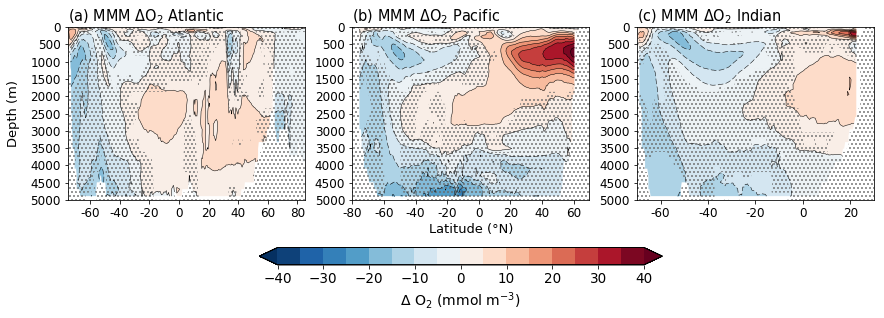

In [26]:
fig = plt.figure(figsize=(14, 3))

axes = []
for i in range(1,3+1):
    ax = fig.add_subplot(1, 3, i)
    axes.append(ax)
    
titles = ['(a) MMM ΔO$_2$ Atlantic', '(b) MMM ΔO$_2$ Pacific', '(c) MMM ΔO$_2$ Indian']
depth = ['depth']*3

simulations = [MMM_diff_atl_cube, MMM_diff_pac_cube, MMM_diff_ind_cube]

for (ax, t, n) in zip(axes, titles, range(np.size(simulations))):
    ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80])
    ax.set_xticklabels([-80, -60, -40, -20, 0, 20, 40, 60, 80])
    ax.set_yticks(np.arange(0, 5000+500, 500))
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    ax.set_ylim(0, 5000)
    
    if n == 2 or n == 5: ## Indian
        ax.set_xlim(-70, 30)
    elif n == 1 or n == 4: ## Pacific
        ax.set_xlim(-80, 70)
    else: ## Atlantic
        ax.set_xlim(-75, 85)
        
    ax.set_title(t, fontsize=14.5, loc='left')
       
    im = iplt.contourf(simulations[n], axes = ax, levels = np.arange(-40, 40+5, 5), cmap = 'RdBu_r', extend = 'both')
    im2 = iplt.contour(simulations[n], axes = ax, colors='k', levels = np.arange(-40, 40+5, 5), linewidths=0.5)

    # Hatching
    mpl.rcParams['hatch.color'] = 'dimgray'
    if n == 0:
        ax.contourf(MMM_diff_atl_cube.coord('latitude').points, MMM_diff_ind_cube.coord('depth').points,
                    non_agreement_atl_thresh, levels=[0.5, 1.5], hatches=['...'], alpha=0, colors='none')
    elif n == 1:
        ax.contourf(MMM_diff_pac_cube.coord('latitude').points, MMM_diff_ind_cube.coord('depth').points,
                    non_agreement_pac_thresh, levels=[0.5, 1.5], hatches=['...'], alpha=0, colors='none')
    else:
        ax.contourf(MMM_diff_ind_cube.coord('latitude').points, MMM_diff_ind_cube.coord('depth').points,
                    non_agreement_ind_thresh, levels=[0.5, 1.5], hatches=['...'], alpha=0, colors='none')
    # Colorbar
    cbar_ax = fig.add_axes([0.29, -0.2, 0.4, 0.08])# [left, bottom, width, height]
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('Δ O$_2$ (mmol m$^{-3}$)', size=14)
    cbar.ax.tick_params(labelsize=13.5)

fig.text(0.04, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=13)
fig.text(0.5, -0.055, 'Latitude (°N)', ha='center', fontsize=13)
plt.subplots_adjust(left=0.1,bottom=0.1,right=0.9,top=0.9,wspace=0.2,hspace=0.4)    
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/O2_MMM_diff_thresh_n_agr_vpaper2.png', bbox_inches='tight', dpi=300, format='png')
plt.show()

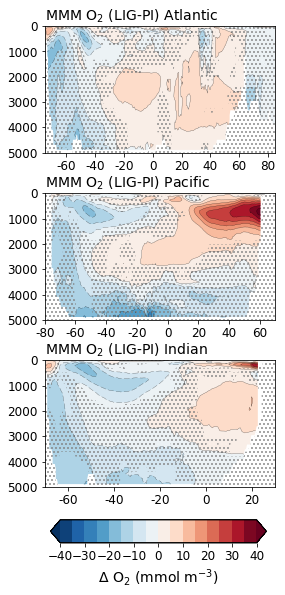

In [27]:
fig = plt.figure(figsize=(4, 8))

axes = []
for i in range(1,3+1):
    ax = fig.add_subplot(3, 1, i)
    axes.append(ax)
    
titles = ['MMM O$_2$ (LIG-PI) Atlantic', 'MMM O$_2$ (LIG-PI) Pacific', 'MMM O$_2$ (LIG-PI) Indian']
depth = ['depth', 'depth', 'depth']

simulations = [MMM_diff_atl_cube, MMM_diff_pac_cube, MMM_diff_ind_cube]

for (ax, t, n) in zip(axes, titles, range(np.size(simulations))):
    ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80])
    ax.set_xticklabels([-80, -60, -40, -20, 0, 20, 40, 60, 80])
    ax.set_yticks(np.arange(0, 5000+1000, 1000))
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    ax.set_ylim(0, 5000)
    
    if n == 2 or n == 5: ## Indian
        ax.set_xlim(-70, 30)
    elif n == 1 or n == 4: ## Pacific
        ax.set_xlim(-80, 70)
    else: ## Atlantic
        ax.set_xlim(-75, 85)
        
    ax.set_title(t, fontsize=14, loc='left')
       
    im = iplt.contourf(simulations[n], axes = ax, levels = np.arange(-40, 40+5, 5), cmap = 'RdBu_r', extend = 'both')
    im2 = iplt.contour(simulations[n], axes = ax, colors='k', levels = np.arange(-40, 40+5, 5), linewidths=0.2)
    # Colourbar
    #cbar_ax = fig.add_axes([0.95, 0.2, 0.05, 0.5])# [left, bottom, width, height]
    #cbar = fig.colorbar(im, cax=cbar_ax)
    #cbar.ax.set_ylabel('Δ O$_2$ (mmolO/m$^3$)', size=14)
    
    cbar_ax = fig.add_axes([0.12, 0.003, 0.75, 0.04])# [left, bottom, width, height]
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('Δ O$_2$ (mmol m$^{-3}$)', size=14)
    cbar.ax.tick_params(labelsize=13.5)
    
    # Hatching
    mpl.rcParams['hatch.color'] = 'gray'
    if n == 0:
        ax.contourf(MMM_diff_atl_cube.coord('latitude').points, MMM_diff_ind_cube.coord('depth').points,
                    non_agreement_atl_thresh, levels=[0.5, 1.5], hatches=['...'], alpha=0, colors='none')
    elif n == 1:
        ax.contourf(MMM_diff_pac_cube.coord('latitude').points, MMM_diff_ind_cube.coord('depth').points,
                    non_agreement_pac_thresh, levels=[0.5, 1.5], hatches=['...'], alpha=0, colors='none')
    else:
        ax.contourf(MMM_diff_ind_cube.coord('latitude').points, MMM_diff_ind_cube.coord('depth').points,
                    non_agreement_ind_thresh, levels=[0.5, 1.5], hatches=['...'], alpha=0, colors='none')
    
    cbar.ax.tick_params(labelsize=12)
    plt.subplots_adjust(left=0.1,bottom=0.1,right=0.9,top=0.9,wspace=0.00,hspace=0.32)    
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/O2_MMM_diff_thresh_n_agr_vposter2.png', bbox_inches='tight', dpi=300, format='png', transparent=True)
plt.show()